[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kulinskij-tech/ClassMech/blob/main/ClassMech_Python/classmech_gencoord.ipynb)


# Generalized coordinates: velocity, acceleration

In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from IPython.display import display
u,v,sigma,tau,alpha = sp.symbols('u v sigma tau alpha',real=True)
ut,vt,sigmat,taut,alphat = sp.symbols('u_t v_t sigma_t tau_t alpha_t',real=True)


def vector_norm_squared(vector):
    # Reduce polynomial trig identities before factoring. This avoids a slow
    # general-purpose trigonometric search for the three-dimensional examples.
    expr=vector.dot(vector)
    atoms=sorted(expr.atoms(sp.sin,sp.cos,sp.sinh,sp.cosh),key=str)
    substitutions={term:sp.Dummy(str(term)) for term in atoms}
    num,den=sp.fraction(sp.cancel(expr.xreplace(substitutions)))
    for term in atoms:
        if term.func not in (sp.sin,sp.sinh): continue
        partner=(sp.cos if term.func==sp.sin else sp.cosh)(term.args[0])
        if partner not in substitutions: continue
        a,b=substitutions[term],substitutions[partner]
        identity=a*a+b*b-1 if term.func==sp.sin else a*a-b*b+1
        num=sp.rem(num,identity,a); den=sp.rem(den,identity,a)
    result=sp.factor(num)/sp.factor(den)
    return result.xreplace({v:k for k,v in substitutions.items()})


def coordinate_grid_2d(expr,variables,first_values,second_values,first_range,second_range,limit=None):
    fn=sp.lambdify(variables,expr,'numpy',cse=True)
    fig,ax=plt.subplots(figsize=(7,6),layout='constrained')
    for fixed in first_values:
        line=np.linspace(*second_range,601)
        with np.errstate(divide='ignore',invalid='ignore'):
            data=np.asarray(fn(np.full_like(line,fixed),line),dtype=float).reshape(2,-1)
        if limit is not None: data[:,np.any(np.abs(data)>limit,axis=0)]=np.nan
        ax.plot(*data,color='tab:blue',linewidth=0.8)
    for fixed in second_values:
        line=np.linspace(*first_range,601)
        with np.errstate(divide='ignore',invalid='ignore'):
            data=np.asarray(fn(line,np.full_like(line,fixed)),dtype=float).reshape(2,-1)
        if limit is not None: data[:,np.any(np.abs(data)>limit,axis=0)]=np.nan
        ax.plot(*data,color='green',linewidth=0.8)
    ax.set(xlabel='x',ylabel='y',aspect='equal')
    if limit is not None: ax.set(xlim=(-limit,limit),ylim=(-limit,limit))
    plt.show()


def coordinate_surfaces(expr,groups,limit=6,axes=None):
    fn=sp.lambdify((sigma,tau,alpha),expr,'numpy',cse=True)
    if axes is None:
        fig=plt.figure(figsize=(7,6),layout='constrained'); axes=fig.add_subplot(projection='3d')
    for fixed_index,fixed_values,range1,range2,opacity in groups:
        varying=[i for i in range(3) if i!=fixed_index]
        a,b=np.meshgrid(np.linspace(*range1,40),np.linspace(*range2,40))
        for j,value in enumerate(fixed_values):
            args=[None]*3
            args[fixed_index]=np.full_like(a,value)
            args[varying[0]]=a; args[varying[1]]=b
            with np.errstate(divide='ignore',invalid='ignore'):
                data=np.asarray(fn(*args),dtype=float).reshape(3,*a.shape)
            data[:,np.any(np.abs(data)>limit,axis=0)]=np.nan
            axes.plot_surface(*data,color=plt.cm.viridis(j/max(1,len(fixed_values)-1)),alpha=opacity,
                              linewidth=0,rstride=2,cstride=2)
    axes.set(xlim=(-limit,limit),ylim=(-limit,limit),zlim=(-limit,limit),xlabel='x',ylabel='y',zlabel='z')
    axes.set_box_aspect((1,1,1))
    return axes

## Velocity and acceleration vectors in general coordinates

An arbitrary coordinate system $q^i$ is characterized by the vectors

$$
{\mathbf{e}}_{i}=\frac{\partial  \mathbf{r}}{\partial  {q}^{i}}\tag{1}
$$

These vectors are tangent to the corresponding coordinate lines and form a basis. The basis need not be orthonormal: its properties depend on the coordinate system. For Cartesian coordinates $\left(x,y,z\right)$:

$$
\mathbf{r}\mathbf{=}x\mathbf{i}\mathbf{+}y\mathbf{j}\mathbf{+}z \mathbf{k}\tag{2}
$$

For spherical coordinates $\left(r,\theta,\varphi\right)$:

$$
\mathbf{r}\mathbf{=}{r\mathbf{e}}_{r}, {\mathbf{e}}_{r}=\sin{\theta}  \cos{\varphi}  \mathbf{i}+\sin{\theta}  \sin{\varphi}  \mathbf{j}+\cos{\theta}   \mathbf{k}\\ {\mathbf{e}}_{\theta }=\frac{\partial \mathbf{r}}{\partial \theta }=r\frac{\partial {\mathbf{e}}_{r}}{\partial \theta }=r\left(\cos{\theta}  \cos{\varphi}  \mathbf{i}+\cos{\theta}  \sin{\varphi}  \mathbf{j}\mathbf{-}\sin{\theta}  \mathbf{k}\right)\perp {\mathbf{e}}_{r},\\ {\mathbf{e}}_{\varphi }=\frac{\partial \mathbf{r}}{\partial \varphi }=r\left(-\sin{\theta}  \sin{\varphi}  \mathbf{i}+\sin{\theta}  \cos{\varphi}  \mathbf{j}\right)=r\frac{\partial {\mathbf{e}}_{r}}{\partial \varphi }\perp {\mathbf{e}}_{r}\tag{3}
$$

the basis vectors are orthogonal.

The metric tensor of the coordinate system is

$$
{d\mathbf{r}}^{2}={g}_{ik}{dq}^{i}{dq}^{k}, {g}_{ik}=\frac{\partial  \mathbf{r}}{\partial  {q}^{i}}\cdot \frac{\partial  \mathbf{r}}{\partial  {q}^{k}}\tag{4}
$$

and the velocity is therefore

$$
\mathbf{v}\mathbf{=}\frac{d\mathbf{r}}{dt}={\dot{q}}^{i}{\mathbf{e}}_{i}\Rightarrow {\mathbf{v}}^{2}={g}_{ik}\frac{{dq}^{i}}{dt}\frac{{dq}^{k}}{dt}\tag{5}
$$

The acceleration is

$$
\mathbf{a}\mathbf{=}\frac{d\mathbf{v}}{dt}={\ddot{q}}^{i}{\mathbf{e}}_{i}+{\dot{q}}^{i}{\dot{q}}^{k}\frac{\partial {\mathbf{e}}_{i}}{\partial {q}^{k}}\tag{6}
$$

The vectors $\partial\mathbf{e}_i/\partial q^k$ can be expanded in the basis $\mathbf{e}_n$:

$$
\frac{\partial {\mathbf{e}}_{i}}{\partial {q}^{k}}={\Gamma }_{ik}^{n} {\mathbf{e}}_{n}, {g}_{nm}{\Gamma }_{ik}^{m}=\left(\frac{\partial {\mathbf{e}}_{i}}{\partial {q}^{k}}\cdot {\mathbf{e}}_{n}\right)\tag{7}
$$

so that

$$
\mathbf{a}=\left({\ddot{q}}^{n}+{\Gamma }_{ik}^{n}{\dot{q}}^{i}{\dot{q}}^{k}\right){\mathbf{e}}_{n}\tag{8}
$$

The quantities $\Gamma^n_{ik}$ are the Christoffel symbols of the second kind. They can be expressed in terms of the metric tensor as follows:

$$
{g}_{nm}{\Gamma }_{ik}^{n}=\left({\mathbf{e}}_{n}\cdot \frac{\partial {\mathbf{e}}_{i}}{\partial {q}^{k}}\right) = \frac{\partial \left({\mathbf{e}}_{i}\cdot {\mathbf{e}}_{n}\right)}{\partial {q}^{k}}-\left({\mathbf{e}}_{i}\cdot \frac{\partial {\mathbf{e}}_{n}}{\partial {q}^{k}}\right)=\frac{\partial  {g}_{in}}{\partial  {q}^{k}}-{g}_{im}{\Gamma }_{kn}^{m}\\ \frac{\partial  {g}_{in}}{\partial  {q}^{k}}={g}_{nm}{\Gamma }_{ik}^{m}+{g}_{im}{\Gamma }_{kn}^{m}\tag{9}
$$

Cyclically permuting the indices gives

$$
\frac{\partial  {g}_{kn}}{\partial  {q}^{i}}={g}_{km}{\Gamma }_{in}^{m}+{g}_{nm}{\Gamma }_{ik}^{m}\\ \frac{\partial  {g}_{ik}}{\partial  {q}^{n}}={g}_{im}{\Gamma }_{nk}^{m}+{g}_{km}{\Gamma }_{in}^{m}\tag{10}
$$

and finally

$$
\frac{\partial  {g}_{kn}}{\partial  {q}^{i}}+\frac{\partial  {g}_{in}}{\partial  {q}^{k}}-\frac{\partial  {g}_{ik}}{\partial  {q}^{n}}=2{g}_{nm}{\Gamma }_{ik}^{m}\Rightarrow {\Gamma }_{ik}^{n}=\frac{{g}^{nm}}{2}\left(\frac{\partial  {g}_{km}}{\partial  {q}^{i}}+\frac{\partial  {g}_{im}}{\partial  {q}^{k}}-\frac{\partial  {g}_{ik}}{\partial  {q}^{m}}\right)\tag{11}
$$

## Elliptic cylindrical coordinates

This coordinate system consists of confocal ellipses and hyperbolas.

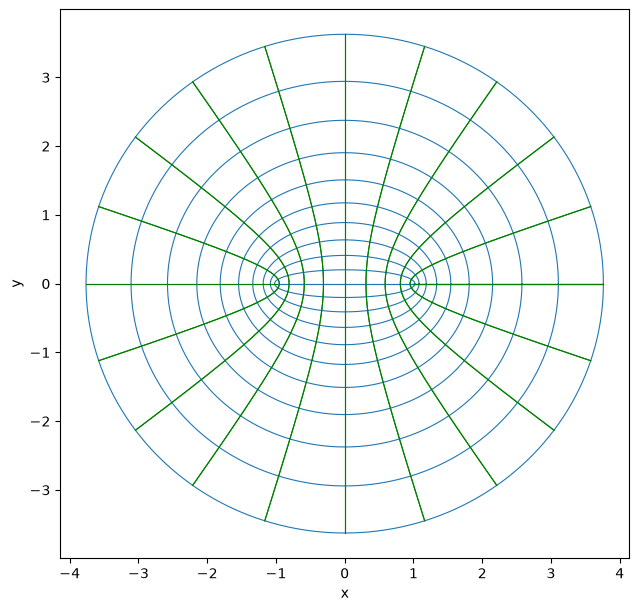

In [2]:
relcyl=sp.Matrix([sp.cosh(u)*sp.cos(v),sp.sinh(u)*sp.sin(v)])
coordinate_grid_2d(relcyl,(u,v),np.arange(0,2.01,0.2),np.arange(0,2*np.pi+0.01,np.pi/10),(-2,2),(0,2*np.pi))

Velocity:

In [3]:
jcyl=relcyl.jacobian([u,v])
velcyl=jcyl*sp.Matrix([ut,vt])
display(jcyl,velcyl,vector_norm_squared(velcyl))

Matrix([
[cos(v)*sinh(u), -sin(v)*cosh(u)],
[sin(v)*cosh(u),  cos(v)*sinh(u)]])

Matrix([
[u_t*cos(v)*sinh(u) - v_t*sin(v)*cosh(u)],
[u_t*sin(v)*cosh(u) + v_t*cos(v)*sinh(u)]])

-(u_t**2 + v_t**2)*(cos(v) - cosh(u))*(cos(v) + cosh(u))

Acceleration:

In [4]:
# As in the source, coordinate rates are held constant here.
# For general motion add jcyl * Matrix([u_tt, v_tt]).
dvcyl=velcyl.jacobian([u,v])
acyl=dvcyl*sp.Matrix([ut,vt])
display(dvcyl,acyl,vector_norm_squared(acyl))

Matrix([
[u_t*cos(v)*cosh(u) - v_t*sin(v)*sinh(u), -u_t*sin(v)*sinh(u) - v_t*cos(v)*cosh(u)],
[u_t*sin(v)*sinh(u) + v_t*cos(v)*cosh(u),  u_t*cos(v)*cosh(u) - v_t*sin(v)*sinh(u)]])

Matrix([
[u_t*(u_t*cos(v)*cosh(u) - v_t*sin(v)*sinh(u)) + v_t*(-u_t*sin(v)*sinh(u) - v_t*cos(v)*cosh(u))],
[ u_t*(u_t*sin(v)*sinh(u) + v_t*cos(v)*cosh(u)) + v_t*(u_t*cos(v)*cosh(u) - v_t*sin(v)*sinh(u))]])

(u_t**2 + v_t**2)**2*(cos(v)**2 + cosh(u)**2 - 1)

## Bipolar coordinates (2D)

This two-dimensional coordinate system consists of two families of orthogonal circles.

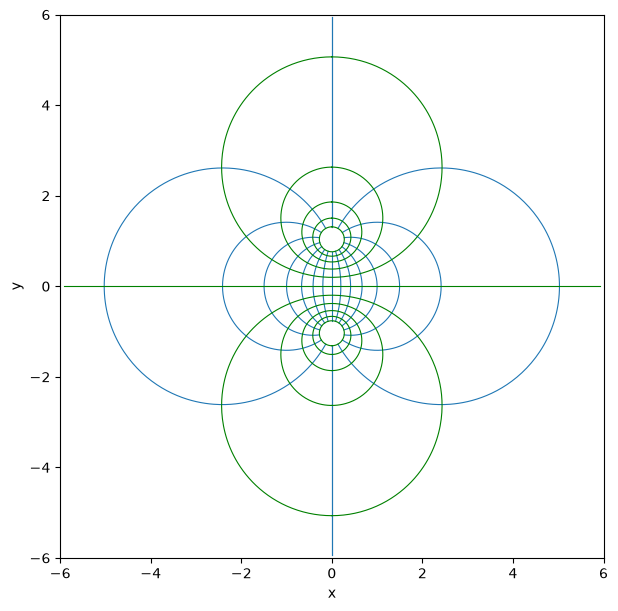

In [5]:
rbip2=sp.Matrix([sp.sin(sigma)/(sp.cosh(tau)-sp.cos(sigma)),sp.sinh(tau)/(sp.cosh(tau)-sp.cos(sigma))])
coordinate_grid_2d(rbip2,(sigma,tau),np.arange(0,2*np.pi+0.01,np.pi/8),np.linspace(-2,2,11),(0,2*np.pi),(-2,2),limit=6)

Velocity

In [6]:
jbip2=rbip2.jacobian([sigma,tau])
velbip2=jbip2*sp.Matrix([sigmat,taut])
display(jbip2,vector_norm_squared(velbip2))

Matrix([
[cos(sigma)/(-cos(sigma) + cosh(tau)) - sin(sigma)**2/(-cos(sigma) + cosh(tau))**2,                              -sin(sigma)*sinh(tau)/(-cos(sigma) + cosh(tau))**2],
[                               -sin(sigma)*sinh(tau)/(-cos(sigma) + cosh(tau))**2, cosh(tau)/(-cos(sigma) + cosh(tau)) - sinh(tau)**2/(-cos(sigma) + cosh(tau))**2]])

(sigma_t**2 + tau_t**2)/(cos(sigma) - cosh(tau))**2

Acceleration:

In [7]:
dvbip2=velbip2.jacobian([sigma,tau])
abip2=dvbip2*sp.Matrix([sigmat,taut])
display(dvbip2,abip2,vector_norm_squared(abip2))

Matrix([
[sigma_t*(-sin(sigma)/(-cos(sigma) + cosh(tau)) - 3*sin(sigma)*cos(sigma)/(-cos(sigma) + cosh(tau))**2 + 2*sin(sigma)**3/(-cos(sigma) + cosh(tau))**3) - tau_t*cos(sigma)*sinh(tau)/(-cos(sigma) + cosh(tau))**2 + 2*tau_t*sin(sigma)**2*sinh(tau)/(-cos(sigma) + cosh(tau))**3,                               sigma_t*(-cos(sigma)*sinh(tau)/(-cos(sigma) + cosh(tau))**2 + 2*sin(sigma)**2*sinh(tau)/(-cos(sigma) + cosh(tau))**3) - tau_t*sin(sigma)*cosh(tau)/(-cos(sigma) + cosh(tau))**2 + 2*tau_t*sin(sigma)*sinh(tau)**2/(-cos(sigma) + cosh(tau))**3],
[                             -sigma_t*cos(sigma)*sinh(tau)/(-cos(sigma) + cosh(tau))**2 + 2*sigma_t*sin(sigma)**2*sinh(tau)/(-cos(sigma) + cosh(tau))**3 + tau_t*(-sin(sigma)*cosh(tau)/(-cos(sigma) + cosh(tau))**2 + 2*sin(sigma)*sinh(tau)**2/(-cos(sigma) + cosh(tau))**3), -sigma_t*sin(sigma)*cosh(tau)/(-cos(sigma) + cosh(tau))**2 + 2*sigma_t*sin(sigma)*sinh(tau)**2/(-cos(sigma) + cosh(tau))**3 + tau_t*(sinh(tau)/(-cos(sigma) + cosh(tau)) - 3*s

Matrix([
[ sigma_t*(sigma_t*(-sin(sigma)/(-cos(sigma) + cosh(tau)) - 3*sin(sigma)*cos(sigma)/(-cos(sigma) + cosh(tau))**2 + 2*sin(sigma)**3/(-cos(sigma) + cosh(tau))**3) - tau_t*cos(sigma)*sinh(tau)/(-cos(sigma) + cosh(tau))**2 + 2*tau_t*sin(sigma)**2*sinh(tau)/(-cos(sigma) + cosh(tau))**3) + tau_t*(sigma_t*(-cos(sigma)*sinh(tau)/(-cos(sigma) + cosh(tau))**2 + 2*sin(sigma)**2*sinh(tau)/(-cos(sigma) + cosh(tau))**3) - tau_t*sin(sigma)*cosh(tau)/(-cos(sigma) + cosh(tau))**2 + 2*tau_t*sin(sigma)*sinh(tau)**2/(-cos(sigma) + cosh(tau))**3)],
[sigma_t*(-sigma_t*cos(sigma)*sinh(tau)/(-cos(sigma) + cosh(tau))**2 + 2*sigma_t*sin(sigma)**2*sinh(tau)/(-cos(sigma) + cosh(tau))**3 + tau_t*(-sin(sigma)*cosh(tau)/(-cos(sigma) + cosh(tau))**2 + 2*sin(sigma)*sinh(tau)**2/(-cos(sigma) + cosh(tau))**3)) + tau_t*(-sigma_t*sin(sigma)*cosh(tau)/(-cos(sigma) + cosh(tau))**2 + 2*sigma_t*sin(sigma)*sinh(tau)**2/(-cos(sigma) + cosh(tau))**3 + tau_t*(sinh(tau)/(-cos(sigma) + cosh(tau)) - 3*sinh(tau)*cosh(tau)/(-

-(sigma_t**2 + tau_t**2)**2*(cos(sigma) + cosh(tau))/(cos(sigma) - cosh(tau))**3

## Bipolar coordinates (3D)

This three-dimensional coordinate system is formed by two families of orthogonal spheres.

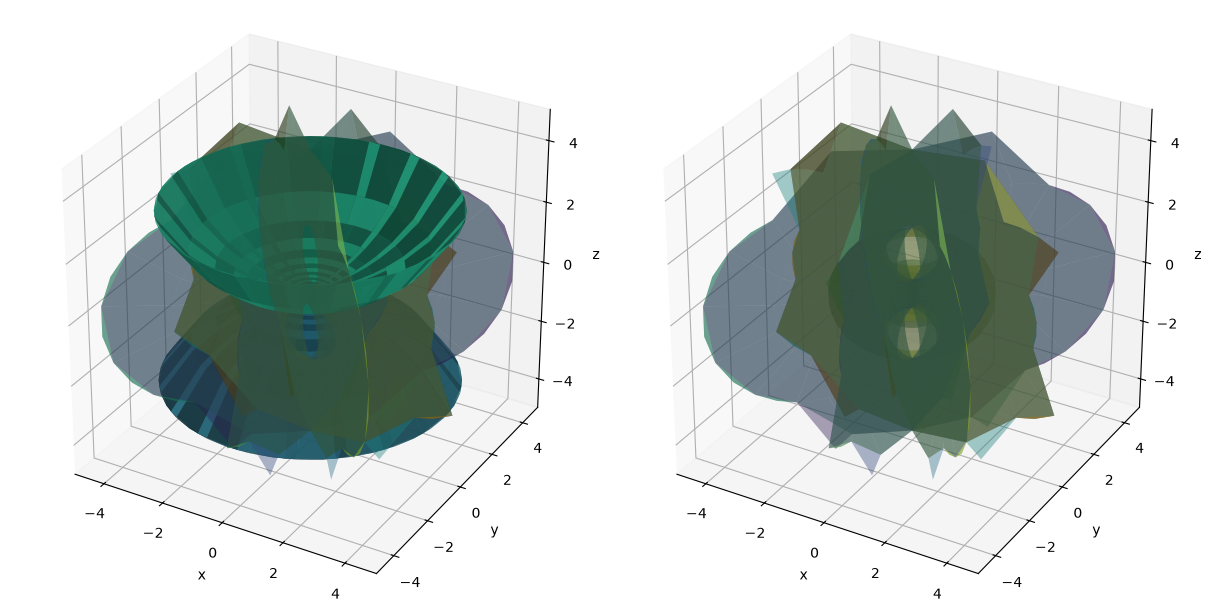

In [8]:
rbip=sp.Matrix([sp.sin(sigma)*sp.cos(alpha),sp.sin(sigma)*sp.sin(alpha),sp.sinh(tau)])/(sp.cosh(tau)-sp.cos(sigma))
fig=plt.figure(figsize=(12,6),layout='constrained')
axes=[fig.add_subplot(1,2,i+1,projection='3d') for i in range(2)]
tau_family=(1,[-1,-0.5,-0.2,0.2,0.5,1],(0,2*np.pi),(0,2*np.pi),0.8)
alpha_family=(2,np.arange(0,2*np.pi+0.01,np.pi/4),(0,2*np.pi),(-1,1),0.4)
sigma_family=(0,np.arange(0,2*np.pi+0.01,np.pi/4),(-1,1),(0,2*np.pi),0.4)
coordinate_surfaces(rbip,[tau_family,alpha_family],limit=5,axes=axes[0])
coordinate_surfaces(rbip,[alpha_family,sigma_family],limit=5,axes=axes[1])
plt.show()

Velocity:

In [9]:
velbip=rbip.jacobian([sigma,tau,alpha])*sp.Matrix([sigmat,taut,alphat])
display(vector_norm_squared(velbip))

-(alpha_t**2*cos(sigma)**2 - alpha_t**2 - sigma_t**2 - tau_t**2)/(cos(sigma) - cosh(tau))**2

Acceleration:

In [10]:
acbip=velbip.jacobian([sigma,tau,alpha])*sp.Matrix([sigmat,taut,alphat])
display(vector_norm_squared(acbip))

-(alpha_t**4*cos(sigma)**3 - alpha_t**4*cos(sigma)**2*cosh(tau) - alpha_t**4*cos(sigma) + alpha_t**4*cosh(tau) + 2*alpha_t**2*sigma_t**2*cos(sigma)**2*cosh(tau) - 4*alpha_t**2*sigma_t**2*cos(sigma) + 2*alpha_t**2*sigma_t**2*cosh(tau) - 4*alpha_t**2*sigma_t*tau_t*sin(sigma)*cos(sigma)*sinh(tau) - 2*alpha_t**2*tau_t**2*cos(sigma)**2*cosh(tau) + 2*alpha_t**2*tau_t**2*cosh(tau) + sigma_t**4*cos(sigma) + sigma_t**4*cosh(tau) + 2*sigma_t**2*tau_t**2*cos(sigma) + 2*sigma_t**2*tau_t**2*cosh(tau) + tau_t**4*cos(sigma) + tau_t**4*cosh(tau))/(cos(sigma) - cosh(tau))**3

## Toroidal coordinates

This three-dimensional coordinate system is obtained by rotating planar bipolar coordinates. Its coordinate surfaces are planes, spheres, and tori.

In [11]:
rtor=sp.Matrix([sp.sinh(tau)*sp.cos(alpha),sp.sinh(tau)*sp.sin(alpha),sp.sin(sigma)])/(sp.cosh(tau)-sp.cos(sigma))

This three-dimensional coordinate system is obtained by rotating planar bipolar coordinates. Its coordinate surfaces are planes, spheres, and tori.

The coordinate surfaces $\tau=\mathrm{const}$ are tori (see bipolar coordinates).

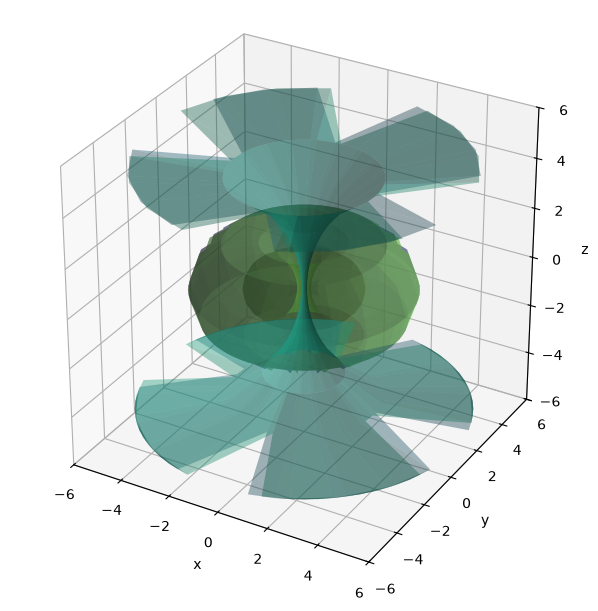

In [12]:
coordinate_surfaces(rtor,[(1,[-1,-0.5,-0.2,0.2,0.5,1],(0,2*np.pi),(0,2*np.pi),0.4)])
plt.show()

The coordinate surfaces $\alpha=\mathrm{const}$ are half-planes.

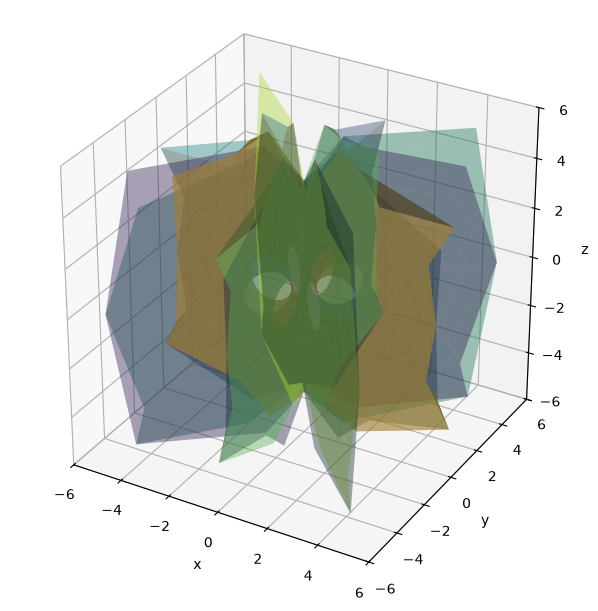

In [13]:
coordinate_surfaces(rtor,[(2,np.arange(0,2*np.pi+0.01,np.pi/4),(0,2*np.pi),(-1,1),0.4)])
plt.show()

The coordinate surfaces $\sigma=\mathrm{const}$ are spheres.

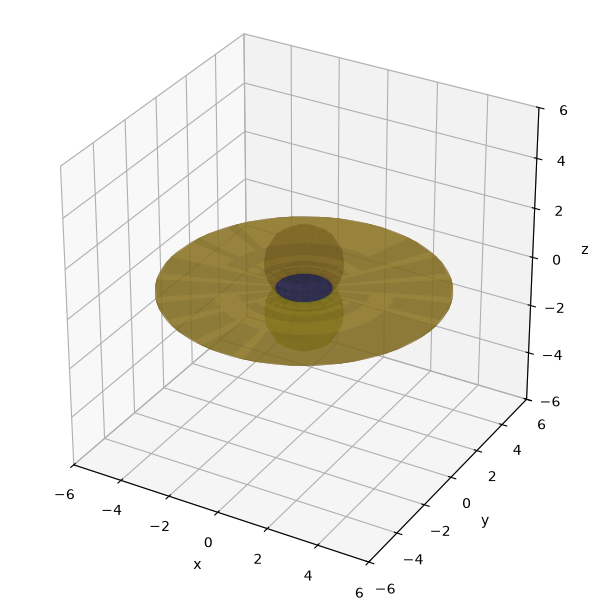

In [14]:
coordinate_surfaces(rtor,[(0,np.arange(0,2*np.pi+0.01,np.pi/4),(-5,5),(0,2*np.pi),0.4)])
plt.show()

Velocity:

In [15]:
veltor=rtor.jacobian([sigma,tau,alpha])*sp.Matrix([sigmat,taut,alphat])
display(vector_norm_squared(veltor))

(alpha_t**2*cosh(tau)**2 - alpha_t**2 + sigma_t**2 + tau_t**2)/(cos(sigma) - cosh(tau))**2

Acceleration:

In [16]:
actor=veltor.jacobian([sigma,tau,alpha])*sp.Matrix([sigmat,taut,alphat])
display(vector_norm_squared(actor))

(alpha_t**4*cos(sigma)*cosh(tau)**2 - alpha_t**4*cos(sigma) - alpha_t**4*cosh(tau)**3 + alpha_t**4*cosh(tau) - 2*alpha_t**2*sigma_t**2*cos(sigma)*cosh(tau)**2 + 2*alpha_t**2*sigma_t**2*cos(sigma) + 4*alpha_t**2*sigma_t*tau_t*sin(sigma)*sinh(tau)*cosh(tau) + 2*alpha_t**2*tau_t**2*cos(sigma)*cosh(tau)**2 + 2*alpha_t**2*tau_t**2*cos(sigma) - 4*alpha_t**2*tau_t**2*cosh(tau) - sigma_t**4*cos(sigma) - sigma_t**4*cosh(tau) - 2*sigma_t**2*tau_t**2*cos(sigma) - 2*sigma_t**2*tau_t**2*cosh(tau) - tau_t**4*cos(sigma) - tau_t**4*cosh(tau))/(cos(sigma) - cosh(tau))**3

[Back to the course contents](https://colab.research.google.com/github/kulinskij-tech/ClassMech/blob/main/ClassMech_Python/classmech_TOC.ipynb)